Install

In [1]:
!pip install -q shap imbalanced-learn

Load Dataset

In [2]:
from google.colab import files
uploaded = files.upload()

Saving synthetic_opd_cohort_500_clean.csv to synthetic_opd_cohort_500_clean.csv


In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

df = pd.read_csv('synthetic_opd_cohort_500_clean.csv')
print(df.shape)
print(df['admission_outcome'].value_counts())
print(df.isna().sum().sum(), 'missing values')
df.head()

(500, 17)
admission_outcome
Discharged    415
Admitted       85
Name: count, dtype: int64
0 missing values


,patient_id,age,gender,symptoms,medical_history,respiratory_rate,spo2,on_oxygen,systolic_bp,diastolic_bp,pulse,temperature_c,consciousness,disease_category,icd10_code,severity,admission_outcome
0,P0001,54,Female,weakness;increased thirst;fatigue;frequent uri...,type 2 diabetes,17,99,0,110,67,76,36.6,Alert,Endocrine_Metabolic,E11.9,Mild,Discharged
1,P0002,21,Female,burning chest;sour burp,obesity;gerd,16,99,0,125,72,79,36.8,Alert,Digestive,K21.9,Mild,Discharged
2,P0003,52,Female,joint pain;breathlessness on exertion;weight g...,hypertension,17,98,0,137,81,53,36.3,Alert,Endocrine_Metabolic,E66.9,Mild,Discharged
3,P0004,44,Female,cold;cough;running nose;mild fever,none,16,96,0,110,59,69,36.6,Alert,Respiratory,J00,Mild,Discharged
4,P0005,57,Female,blurred vision;dizziness;fatigue;palpitations,smoking;diabetes,16,99,0,127,70,82,36.7,Alert,Circulatory,I10,Mild,Discharged


Preprocessing

In [4]:
y = (df['admission_outcome'] == 'Admitted').astype(int)
numeric = ['age','respiratory_rate','spo2','on_oxygen','systolic_bp','diastolic_bp','pulse','temperature_c']
categorical = ['gender','consciousness','disease_category']

X = pd.get_dummies(df[numeric + categorical], columns=categorical, dtype=int)
print(X.shape)
X.head()

(500, 19)


,age,respiratory_rate,spo2,on_oxygen,systolic_bp,diastolic_bp,pulse,temperature_c,gender_Female,gender_Male,gender_Other,consciousness_Alert,consciousness_Confusion,consciousness_Voice,disease_category_Circulatory,disease_category_Digestive,disease_category_Endocrine_Metabolic,disease_category_Musculoskeletal,disease_category_Respiratory
0,54,17,99,0,110,67,76,36.6,1,0,0,1,0,0,0,0,1,0,0
1,21,16,99,0,125,72,79,36.8,1,0,0,1,0,0,0,1,0,0,0
2,52,17,98,0,137,81,53,36.3,1,0,0,1,0,0,0,0,1,0,0
3,44,16,96,0,110,59,69,36.6,1,0,0,1,0,0,0,0,0,0,1
4,57,16,99,0,127,70,82,36.7,1,0,0,1,0,0,1,0,0,0,0


Split and SMOTE

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(X_train[numeric])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[numeric] = scaler.transform(X_train[numeric])
X_test_s[numeric] = scaler.transform(X_test[numeric])

print('before SMOTE:', y_train.value_counts().to_dict())
X_res, y_res = SMOTE(random_state=42).fit_resample(X_train_s, y_train)
print('after SMOTE: ', y_res.value_counts().to_dict())

before SMOTE: {0: 332, 1: 68}
after SMOTE:  {0: 332, 1: 332}


train the two models. Random Forest is many decision trees voting together. XGBoost builds trees one after another, each fixing the mistakes of the last.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_res, y_res)
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                    eval_metric='logloss', random_state=42).fit(X_res, y_res)
print('trained')

trained


evaluate and compare. On the untouched test set we measure accuracy, precision, recall, F1 and ROC-AUC. Recall matters most here, because it shows how many truly sick (admitted) patients the model catches

In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

rows = {}
for name, model in [('Random Forest', rf), ('XGBoost', xgb)]:
    pred = model.predict(X_test_s)
    prob = model.predict_proba(X_test_s)[:, 1]
    rows[name] = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
                  'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
                  'ROC-AUC': roc_auc_score(y_test, prob)}
results = pd.DataFrame(rows).T.round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest,0.80,0.400,0.353,0.375,0.726
XGBoost,0.81,0.444,0.471,0.457,0.757


Confusion matrix

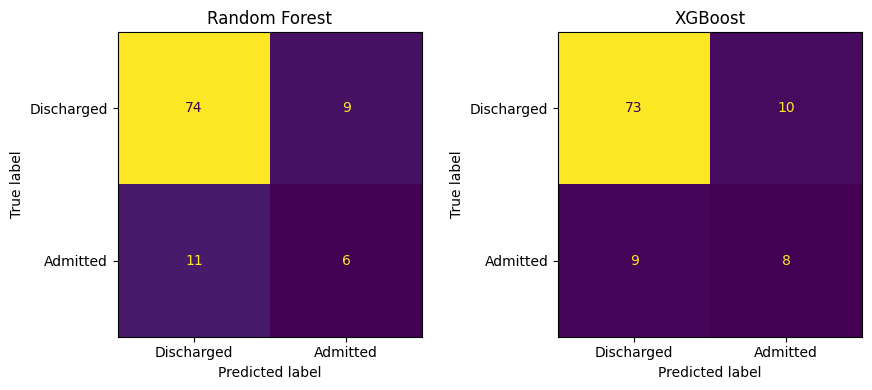

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, model) in zip(axes, [('Random Forest', rf), ('XGBoost', xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test_s)),
                           display_labels=['Discharged', 'Admitted']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

SHAP, why did the model decide that?

In [9]:
import shap

best_name = results['F1'].idxmax()
best_model = {'Random Forest': rf, 'XGBoost': xgb}[best_name]
print('Explaining:', best_name)

explainer = shap.TreeExplainer(best_model)
sv = explainer.shap_values(X_test_s)
if isinstance(sv, list):             # older shap: one array per class
    sv = sv[1]
elif getattr(sv, 'ndim', 2) == 3:    # newer shap: (rows, features, classes)
    sv = sv[:, :, 1]

Explaining: XGBoost


SHAP summary plot

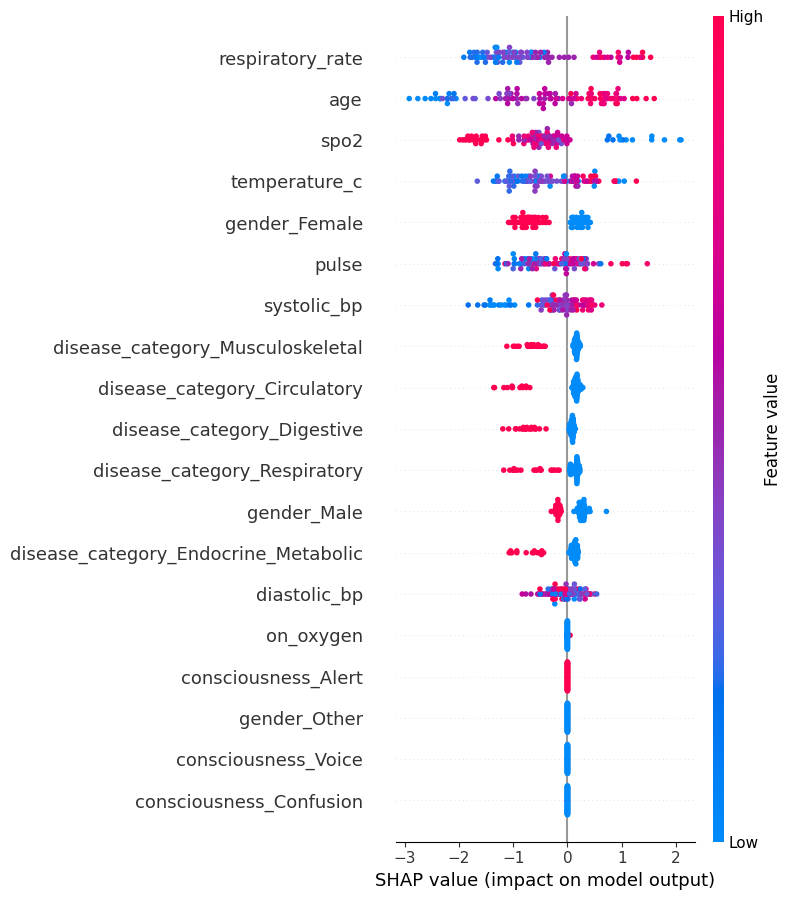

In [10]:
shap.summary_plot(sv, X_test_s, show=False)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

SHAP bar plot

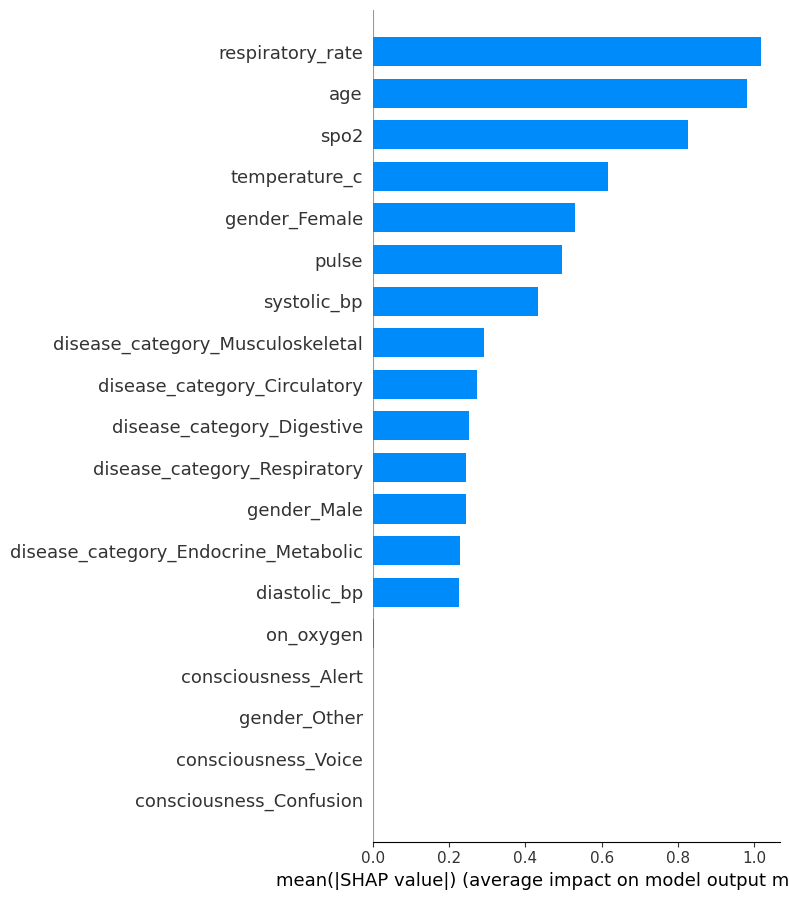

In [11]:
shap.summary_plot(sv, X_test_s, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

top 3 risk factors for one patient.

In [12]:
def top3_risk_factors(row_index):
    contrib = pd.Series(sv[row_index], index=X_test_s.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:3]
    return [{'factor': f, 'impact': round(float(v), 3)} for f, v in top.items()]

print(top3_risk_factors(0))

[{'factor': 'disease_category_Musculoskeletal', 'impact': -0.669}, {'factor': 'age', 'impact': 0.504}, {'factor': 'respiratory_rate', 'impact': 0.475}]
